In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(6)

def true_brightness(t):
    return 10.0 + 0.04 * t + 0.9 * np.sin(2 * np.pi * t / 9.0 + 0.6)

t = np.sort(np.concatenate([rng.uniform(0, 17, 16), rng.uniform(27, 40, 12)]))
N = t.size

sigma = rng.uniform(0.15, 0.35, N)
bad = rng.choice(N, 5, replace=False)
sigma[bad] = rng.uniform(0.6, 0.9, bad.size)

y = true_brightness(t) + sigma * rng.normal(size=N)

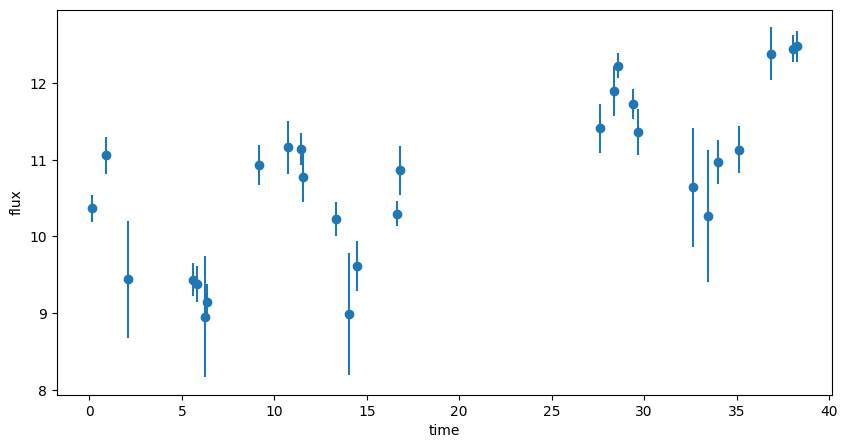

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(t, y, yerr=sigma, fmt="o")
ax.set_ylabel('flux')
ax.set_xlabel('time')
plt.show()

$$y_i = b + m\,t_i + \varepsilon_i,\qquad \varepsilon_i \sim \mathcal N(0, \sigma_i^2)$$

$$
\mathbf y = A\mathbf w + \boldsymbol\varepsilon,\qquad
A = \begin{bmatrix} 1 & t_1\\ 1 & t_2\\ \vdots & \vdots\\ 1 & t_N\end{bmatrix},\qquad
\mathbf w = \begin{bmatrix} b\\ m\end{bmatrix}
$$

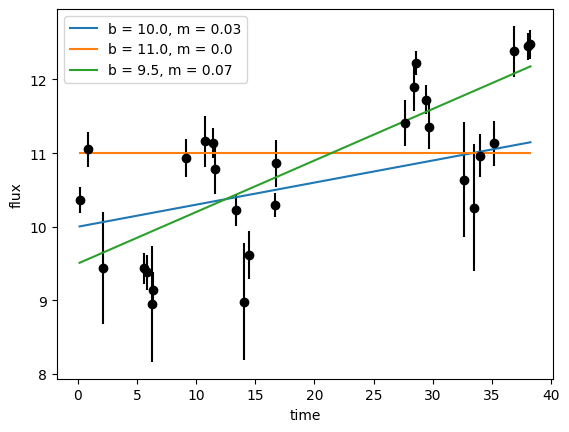

In [5]:
A = np.column_stack([np.ones(N), t])

plt.errorbar(t, y, sigma, fmt='ko')
for b, m in [(10.0, 0.03), (11.0, 0.0), (9.5, 0.07)]:
    plt.plot(t, b + m*t, label=f'b = {b}, m = {m}')
plt.legend()
plt.xlabel('time')
plt.ylabel('flux')
plt.show()

$$
\chi^2(\mathbf w) = \sum_{i=1}^N \frac{(y_i - b - m\,t_i)^2}{\sigma_i^2}
= (\mathbf y - A\mathbf w)^\top C^{-1}(\mathbf y - A\mathbf w),
\qquad C = \mathrm{diag}(\sigma_1^2, \ldots, \sigma_N^2)
$$

$$
\chi^2(\mathbf w) = \mathbf y^\top C^{-1}\mathbf y - 2\,\mathbf w^\top A^\top C^{-1}\mathbf y + \mathbf w^\top A^\top C^{-1}A\,\mathbf w
$$

$$
\partial \chi^2/\partial \mathbf{w} = -2A^\top C^{-1}\mathbf y + 2A^\top C^{-1}A\,\mathbf w = 0
\quad\Rightarrow\quad
\boxed{\hat{\mathbf w} = (A^\top C^{-1}A)^{-1}A^\top C^{-1}\mathbf y}
$$

This $\hat{\mathbf w}$ is the best fit line, i.e. this set of $b$ and $m$ is the best fit line.

In [ ]:
Cinv = np.diag(1 / sigma**2)                   # inverse noise covariance (diagonal)

Sigma_w = np.linalg.inv(A.T @ Cinv @ A)        # (A^T C^-1 A)^-1 
w_hat   = Sigma_w @ A.T @ Cinv @ y             # best fit b, m

resid = y - A @ w_hat
chi2  = resid @ Cinv @ resid
dof   = N - 2
b_hat, m_hat = w_hat
print(f"fit:  b = {b_hat},  m = {m_hat}")
print(f"chi^2 = {chi2} for {dof} degrees of freedom  ->  chi^2/dof = {chi2/dof}")

fit:  b = 9.778009461364343,  m = 0.06315410302593542
chi^2 = 175.9630449169382 for 26 degrees of freedom  ->  chi^2/dof = 6.767809419882239


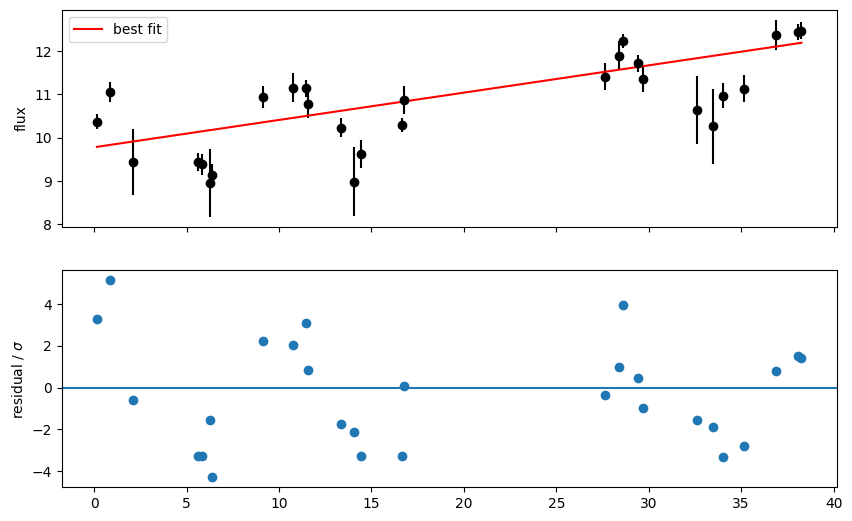

In [10]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
ax.errorbar(t, y, yerr=sigma, fmt="ko")
ax.plot(t, A @ w_hat, color='r',label="best fit")
ax.set_ylabel("flux")
ax.legend(loc="upper left")

axr.axhline(0)
axr.plot(t, resid / sigma, "o", ms=6)
axr.set_ylabel(r"residual / $\sigma$")
plt.show()

$$
p(y_i \mid \mathbf w) = \frac{1}{\sqrt{2\pi\sigma_i^2}}\exp\!\left[-\frac{(y_i - b - m\,t_i)^2}{2\sigma_i^2}\right]
$$

$$
\mathcal L(\mathbf w) = \prod_{i=1}^N p(y_i \mid \mathbf w)
= \mathcal N(\mathbf y \mid A\mathbf w,\ C)
= \frac{1}{\sqrt{|2\pi C|}}\exp\!\left[-\tfrac12(\mathbf y - A\mathbf w)^\top C^{-1}(\mathbf y - A\mathbf w)\right]
$$

$$
-2\ln\mathcal L(\mathbf w) = \chi^2(\mathbf w) + \ln|2\pi C|
$$

$$
\mathcal L(\mathbf w) \propto \exp\!\left[-\tfrac12(\mathbf w - \hat{\mathbf w})^\top \Sigma_w^{-1}(\mathbf w - \hat{\mathbf w})\right],
\qquad \Sigma_w = (A^\top C^{-1}A)^{-1}
$$

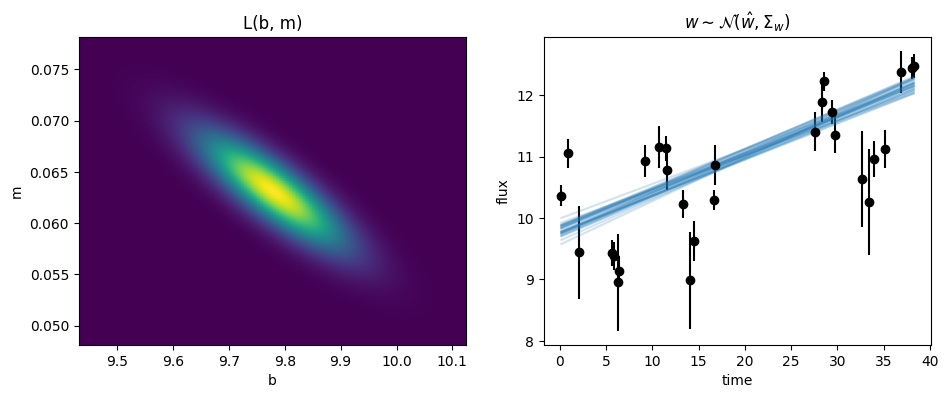

In [19]:
sb, sm = np.sqrt(np.diag(Sigma_w))
bs = np.linspace(w_hat[0] - 4*sb, w_hat[0] + 4*sb, 120)
ms = np.linspace(w_hat[1] - 4*sm, w_hat[1] + 4*sm, 120)
X2 = np.array([[np.sum((y - b - m*t)**2/sigma**2) for b in bs] for m in ms])


from scipy.stats import multivariate_normal
lnL = multivariate_normal(A @ w_hat, np.diag(sigma**2)).logpdf(y)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(np.exp(-0.5*X2), origin='lower', aspect='auto',
             extent=[bs[0], bs[-1], ms[0], ms[-1]])
ax[0].set_xlabel('b')
ax[0].set_ylabel('m')
ax[0].set_title('L(b, m)')
ax[1].errorbar(t, y, sigma, fmt='ko')
for w in rng.multivariate_normal(w_hat, Sigma_w, 30):
    ax[1].plot(t, w[0] + w[1]*t, 'C0', alpha=0.2)
ax[1].set_xlabel('time')
ax[1].set_ylabel('flux')
ax[1].set_title(r'$w \sim \mathcal{N}(\hat{w}, \Sigma_w)$')
plt.show()

$$r_i = y_i - (b + m\,t_i)$$

$$
corr(\Delta t) = \frac{\sum_{(i,j)} r_i\, r_j}{\sqrt{\sum_{(i,j)} r_i^2\ \sum_{(i,j)} r_j^2}},
\qquad \text{pairs } (i,j)
$$

$$
\begin{bmatrix} r_i\\ r_j\end{bmatrix} \sim
\mathcal N\!\left(\begin{bmatrix} 0\\ 0\end{bmatrix},\
\sigma_r^2\begin{bmatrix} 1 & corr(\Delta)\\ corr(\Delta) & 1\end{bmatrix}\right)
$$

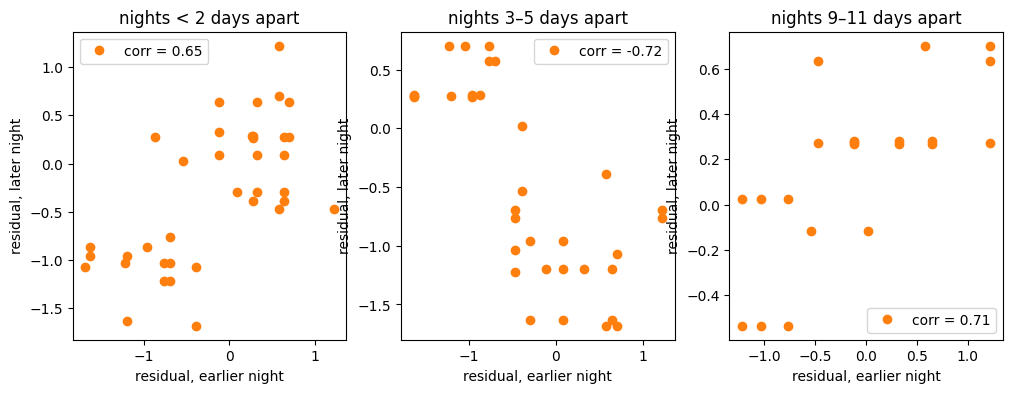

In [46]:
I, J = np.triu_indices(N, 1)         
sep = t[J] - t[I]                     # how far apart the two nights are 
SEP_BINS = [(0, 2), (3, 5), (9, 11)]       

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (lo, hi) in zip(axes, SEP_BINS):
    m = (sep > lo) & (sep < hi)
    x1, x2 = resid[I[m]], resid[J[m]]
    ax.plot(x1, x2, "o", color='C1', label=f"corr = {np.corrcoef(x1, x2)[0, 1]:.2f}")

    ax.set_xlabel("residual, earlier night")
    ax.set_ylabel("residual, later night")
    label = f"< {hi:g}" if lo == 0 else f"{lo:g}–{hi:g}"
    ax.set_title(f"nights {label} days apart")
    ax.legend()
plt.show()

In [18]:
def gauss1d(x, mu, s):
    return np.exp(-0.5*((x - mu)/s)**2) / np.sqrt(2*np.pi*s**2)

$$
p(x_2 \mid x_1) = \frac{p(x_1\mid x_2)p(x_2)}{p(x_1)}
$$

$$
p(\mathbf x) = \frac{1}{\sqrt{|2\pi\Sigma|}}\exp\!\left[-\tfrac12(\mathbf x - \boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x - \boldsymbol\mu)\right],
\qquad
\mathbf x = \begin{bmatrix} x_1\\ x_2\end{bmatrix},\quad
\Sigma = \begin{bmatrix} \Sigma_{11} & \Sigma_{12}\\ \Sigma_{21} & \Sigma_{22}\end{bmatrix}
$$

Assume that the two variables follow a joint Gaussian distribution:
$$
\begin{bmatrix}
x_1\\x_2
\end{bmatrix}
\sim
\mathcal N\left(
\begin{bmatrix}
\mu_1\\\mu_2
\end{bmatrix},
\begin{bmatrix}
\Sigma_{11}&\Sigma_{12}\\
\Sigma_{21}&\Sigma_{22}
\end{bmatrix}
\right)
$$

We want to find the distribution of $\mathbf{x}_2$ given that we observe $\mathbf{x}_1$.

Define

$$
\mathbf{z} = \mathbf{x}_2-\Sigma_{21}\Sigma_{11}^{-1}\mathbf{x}_1,
$$

so that $\mathbf{z}$ is uncorrelated with $\mathbf{x}_1$:

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{z},\mathbf{x}_1)
&=
\operatorname{Cov}(\mathbf{x}_2-\Sigma_{21}\Sigma_{11}^{-1}\mathbf{x}_1,\mathbf{x}_1)\\
&=\Sigma_{21}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{11}\\
&=0.
\end{aligned}
$$

$$
\begin{aligned}
\boldsymbol{\mu}_z
&=\mathbb{E}[\mathbf{x}_2-\Sigma_{21}\Sigma_{11}^{-1}\mathbf{x}_1]\\
&=\boldsymbol{\mu}_2-\Sigma_{21}\Sigma_{11}^{-1}\boldsymbol{\mu}_1.
\end{aligned}
$$


(Using:

$$
\operatorname{Var}(X-aY)
=
\operatorname{Var}(X)
+a^2\operatorname{Var}(Y)
-2a\operatorname{Cov}(X,Y).
$$)


$$
\begin{aligned}
\operatorname{Cov}(\mathbf{z})
={}&\operatorname{Cov}(\mathbf{x}_2)
+\Sigma_{21}\Sigma_{11}^{-1}\operatorname{Cov}(\mathbf{x}_1)(\Sigma_{21}\Sigma_{11}^{-1})^\top\\
&-\operatorname{Cov}(\mathbf{x}_2,\mathbf{x}_1)(\Sigma_{21}\Sigma_{11}^{-1})^\top\\
&-\Sigma_{21}\Sigma_{11}^{-1}\operatorname{Cov}(\mathbf{x}_1,\mathbf{x}_2).
\end{aligned}
$$

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{z})
={}&\Sigma_{22}
+\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{11}(\Sigma_{21}\Sigma_{11}^{-1})^\top\\
&-\Sigma_{21}(\Sigma_{21}\Sigma_{11}^{-1})^\top-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}.
\end{aligned}
$$

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{z})
={}&\Sigma_{22}\\
&+\Sigma_{21}\Sigma_{11}^{-1}
\Sigma_{11}\Sigma_{11}^{-1}\Sigma_{12}\\
&-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}\\
&-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}.
\end{aligned}
$$

$$
\operatorname{Cov}(\mathbf{z})
=
\Sigma_{22}-
\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}
$$

We can rearrange our definition of $\mathbf{z}$:

$$
\mathbf{x}_2=\mathbf{z}+\Sigma_{21}\Sigma_{11}^{-1}\mathbf{x}_1.
$$

In particular, given $\mathbf{x}_1=\mathbf{a}$:

$$
\mathbf{x}_2\mid\mathbf{x}_1=\mathbf{a}
=
\mathbf{z}+\Sigma_{21}\Sigma_{11}^{-1}\mathbf{a}.
$$

Adding a constant shifts the mean but does not change the covariance. Therefore,

$$
\boxed{
\begin{aligned}
\boldsymbol{\mu}_{2|1}
&=
\boldsymbol{\mu}_2+
\Sigma_{21}\Sigma_{11}^{-1}
(\mathbf{a}-\boldsymbol{\mu}_1),\\[6pt]
\Sigma_{2|1}
&=
\Sigma_{22}-
\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}.
\end{aligned}
}
$$

Let's see what conditioning looks like visually

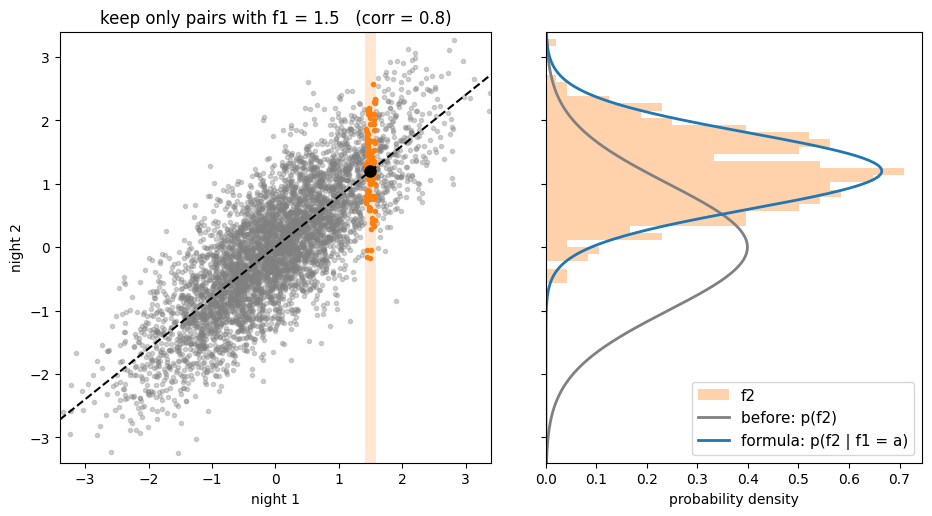

In [21]:
corr = 0.8    
a   = 1.5    

C   = np.array([[1, corr], [corr, 1]])
mu  = np.array([0.0, 0.0])

mu_c  = mu[1] + C[1, 0] / C[0, 0] * (a - mu[0])     # the formula
var_c = C[1, 1] - C[1, 0] / C[0, 0] * C[0, 1]
sd_c  = np.sqrt(var_c)

draws = rng.multivariate_normal(mu, C, 20000)      # every pair the star could have had
keep  = np.abs(draws[:, 0] - a) < 0.08                # f1 = a
show  = draws[:5000]
show_keep = np.abs(show[:, 0] - a) < 0.08

fig, (ax, axp) = plt.subplots(1, 2, figsize=(11.5, 5.6), sharey=True,
                              gridspec_kw=dict(width_ratios=[1.3, 1], wspace=0.06))
ax.plot(show[~show_keep, 0], show[~show_keep, 1], ".", color='gray', alpha=0.35)
ax.axvspan(a - 0.08, a + 0.08, color='C1', alpha=0.18, lw=0)
ax.plot(show[show_keep, 0], show[show_keep, 1], ".", color='C1')
g = np.linspace(-3.4, 3.4, 10)
ax.plot(g, mu[1] + C[1, 0] / C[0, 0] * (g - mu[0]), color='k', ls="--", lw=1.5)
ax.plot(a, mu_c, "o", color='k', ms=8, zorder=5)
ax.set_xlim(-3.4, 3.4); 
ax.set_ylim(-3.4, 3.4); 
ax.set_aspect("equal")
ax.set_xlabel("night 1")
ax.set_ylabel("night 2")
ax.set_title(f"keep only pairs with f1 = {a}   (corr = {corr})")

gg = np.linspace(-3.4, 3.4, 400)
axp.hist(draws[keep, 1], bins=60, range=(-3.4, 3.4), density=True, orientation="horizontal",
        color='C1', alpha=0.35, label=f"f2")
axp.plot(gauss1d(gg, mu[1], np.sqrt(C[1, 1])), gg, color='gray', lw=2, label="before: p(f2)")
axp.plot(gauss1d(gg, mu_c, sd_c), gg, color='C0', lw=2, label="formula: p(f2 | f1 = a)")
axp.set_xlabel("probability density")
axp.legend(loc="lower right", fontsize=11)
plt.show()

$$
f(t) = w_0 + w_1 s + w_2 s^2 = \mathbf a(t)^\top\mathbf w,\qquad
\mathbf a(t) = \begin{bmatrix} 1\\ s\\ s^2\end{bmatrix},\qquad s = \frac{t - 20}{20}
$$

$$
\mathbf w \sim \mathcal N(0, \Lambda)
\quad\Rightarrow\quad
\mathbf f = A\mathbf w \sim \mathcal N(0,\ A\Lambda A^\top),
\qquad
\mathrm{Cov}\big(f(t), f(t')\big) = \mathbf a(t)^\top\Lambda\,\mathbf a(t')
$$

$$
\begin{bmatrix} \mathbf y\\ \mathbf f_*\end{bmatrix} \sim
\mathcal N\!\left(\mathbf 0,\
\begin{bmatrix} K + C & K_*\\ K_*^\top & K_{**}\end{bmatrix}\right),
\qquad K = A\Lambda A^\top,\quad K_* = A\Lambda A_*^\top,\quad K_{**} = A_*\Lambda A_*^\top
$$

$$
\boxed{\ \boldsymbol\mu_* = K_*^\top(K + C)^{-1}\mathbf y,
\qquad
\Sigma_* = K_{**} - K_*^\top(K + C)^{-1}K_*\ }
$$

$$
\boldsymbol\mu_* = A_*\big(A^\top C^{-1}A + \Lambda^{-1}\big)^{-1}A^\top C^{-1}\mathbf y
\ \xrightarrow{\ \Lambda \to \infty\ }\ A_*\hat{\mathbf w}
$$

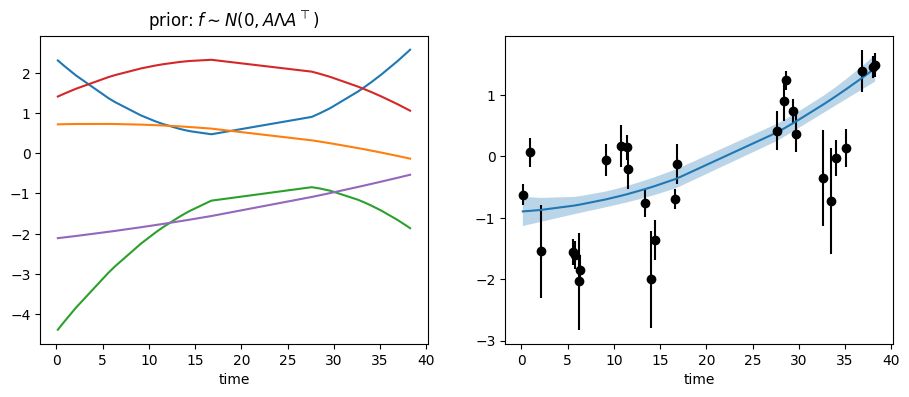

In [24]:
ybar = np.average(y, weights=1/sigma**2)
y0 = y - ybar
Cn = np.diag(sigma**2)

def Aq(t):
    s = (t - 20)/20
    return np.column_stack([np.ones_like(s), s, s**2])

def predict(Af, Lam, tnew):
    K, Ks, Kss = Af(t) @ Lam @ Af(t).T, Af(t) @ Lam @ Af(tnew).T, Af(tnew) @ Lam @ Af(tnew).T
    mu = Ks.T @ np.linalg.solve(K + Cn, y0)
    cov = Kss - Ks.T @ np.linalg.solve(K + Cn, Ks)
    return mu, np.sqrt(np.clip(np.diag(cov), 0, None))

Lam_q = np.diag([1.0, 1.0, 1.0])
mu_q, sd_q = predict(Aq, Lam_q, t)

mu_big, _ = predict(Aq, 1e4*Lam_q, t)
wq = np.linalg.solve(Aq(t).T @ Cinv @ Aq(t), Aq(t).T @ Cinv @ y0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, Aq(t) @ rng.multivariate_normal(np.zeros(3), Lam_q, 5).T)
ax[0].set_xlabel('time'); 
ax[0].set_title(r'prior: $f \sim N(0, A\Lambda A^\top)$')
ax[1].errorbar(t, y0, sigma, fmt='ko')
ax[1].plot(t, mu_q); ax[1].fill_between(t, mu_q - 2*sd_q, mu_q + 2*sd_q, alpha=0.3)
ax[1].set_xlabel('time')
plt.show()

$$
f(t) = a_0 + \sum_{k=1}^{K}\left[a_k\cos\frac{2\pi k t}{T} + b_k\sin\frac{2\pi k t}{T}\right]
$$

$$
a_0 \sim \mathcal N(0, s_0^2),\qquad a_k,\ b_k \sim \mathcal N(0, s_k^2)
$$

$$
\mathrm{Cov}\big(f(t), f(t')\big)
= s_0^2 + \sum_{k=1}^{K} s_k^2\left[\cos\frac{2\pi k t}{T}\cos\frac{2\pi k t'}{T} + \sin\frac{2\pi k t}{T}\sin\frac{2\pi k t'}{T}\right]
$$

$$
\boxed{\ k(t, t') = s_0^2 + \sum_{k=1}^{K} s_k^2\cos\frac{2\pi k\,(t - t')}{T}\ }
$$

$$
s_k = s\quad (k = 1, \ldots, K)
$$

$$
\boldsymbol\mu_* = K_*^\top(K + C)^{-1}\mathbf y,\qquad
\Sigma_* = K_{**} - K_*^\top(K + C)^{-1}K_*,\qquad
K_{ij} = k(t_i, t_j)
$$

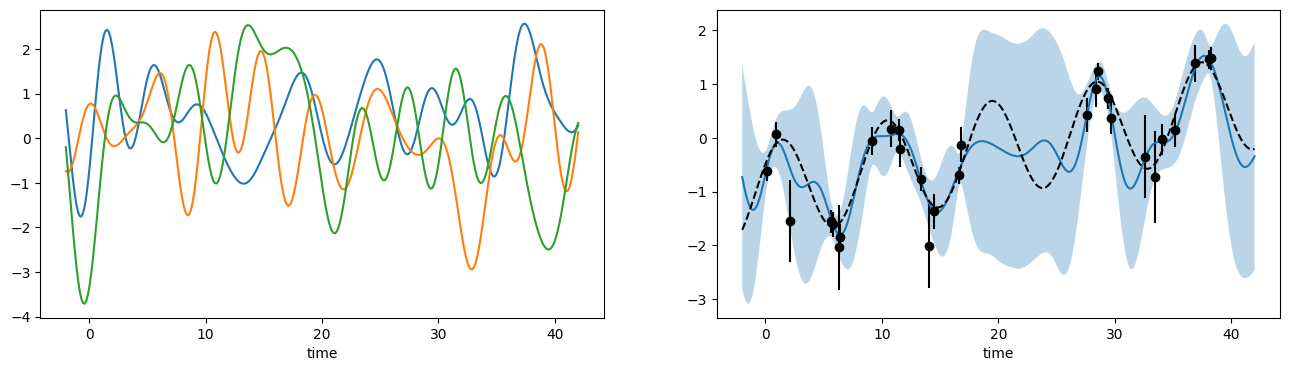

In [40]:
T, Kmax = 90.0, 25
s0, s = np.sqrt(0.2*np.var(y0)), np.sqrt(np.var(y0)/Kmax)

def Af(t):
    ph = 2*np.pi*np.outer(t, np.arange(1, Kmax + 1))/T
    return np.column_stack([np.ones_like(t), np.cos(ph), np.sin(ph)])
Lam_f = np.diag(np.r_[s0**2, np.full(2*Kmax, s**2)])

def kern(d):
    return s0**2 + s**2*np.cos(2*np.pi*np.outer(d, np.arange(1, Kmax + 1))/T).sum(1)

D = (t[:, None] - t[None, :]).ravel()

tt = np.linspace(-2, 42, 300)
mu_f, sd_f = predict(Af, Lam_f, tt)
Sp = np.linalg.inv(Af(t).T @ Cinv @ Af(t) + np.linalg.inv(Lam_f))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(tt, Af(tt) @ rng.multivariate_normal(np.zeros(2*Kmax + 1), Lam_f, 3).T)
ax[0].set_xlabel('time')
ax[1].errorbar(t, y0, sigma, fmt='ko')
ax[1].plot(tt, mu_f) 
ax[1].plot(tt, true_brightness(tt)-ybar,'k--')
ax[1].fill_between(tt, mu_f - 2*sd_f, mu_f + 2*sd_f, alpha=0.3)
ax[1].set_xlabel('time')
plt.show()

In [109]:
ell   = 2.0  # width of each bump 
dc    = 1.0   # spacing between bump centres
lam   = 0.6   # prior std of each bump's weight
centres = np.arange(-1, 40, dc)
M = centres.size

def Phi(times):
    # design matrix: rows = times, columns = bumps (each column is one fixed shape)
    x = (times[:, None] - centres[None, :]) / ell
    return np.exp(-0.5 * x**2)                         # bell-shaped hills

ybar = np.sum(y / sigma**2) / np.sum(1 / sigma**2)   # weighted mean flux
yc = y - ybar

A_b  = Phi(t)                      # N x M   (28 x 49)
tt   = np.linspace(-1, 40, 400)
A_bs = Phi(tt)                     # design matrix at prediction times

# with a prior  w ~ N(0, lam^2 I):   Sigma_post = (A^T C^-1 A + Lambda^-1)^-1
Lam_inv    = np.eye(M) / lam**2
Sigma_post = np.linalg.inv(A_b.T @ Cinv @ A_b + Lam_inv)
mu_post    = Sigma_post @ A_b.T @ Cinv @ yc

f_ws  = ybar + A_bs @ mu_post                                         # posterior mean light curve
sd_ws = np.sqrt(np.einsum("ij,jk,ik->i", A_bs, Sigma_post, A_bs))     # posterior std 
print(f"M = {M} bumps for N = {N} data points")

M = 41 bumps for N = 28 data points


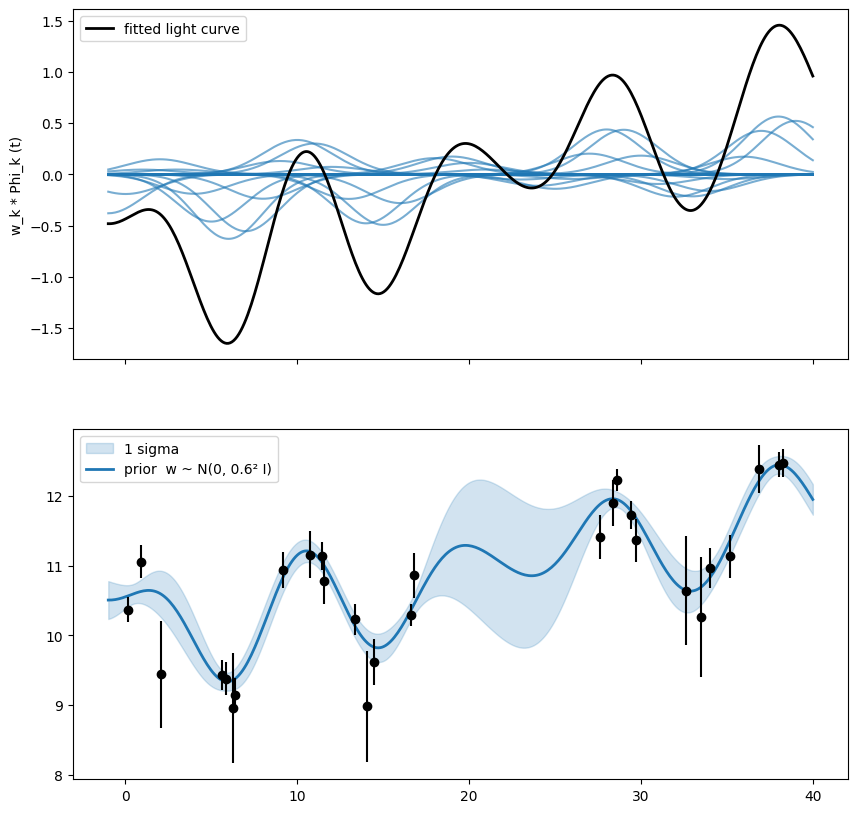

In [113]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True,)
ax1, ax2 = axes
for k in range(M):
    ax1.plot(tt, mu_post[k] * A_bs[:, k], color='C0', alpha=0.6)
ax1.plot(tt, A_bs @ mu_post, color='k', lw=2, label="fitted light curve")
ax1.set_ylabel("w_k * Phi_k (t)")
ax1.legend()

ax2.fill_between(tt, f_ws - sd_ws, f_ws + sd_ws, color='C0', alpha=0.2, label="1 sigma")
ax2.plot(tt, f_ws, color='C0', lw=2, label=f"prior  w ~ N(0, {lam}² I)")
ax2.errorbar(t, y, yerr=sigma, fmt='o', color='black')
ax2.legend()
plt.show()

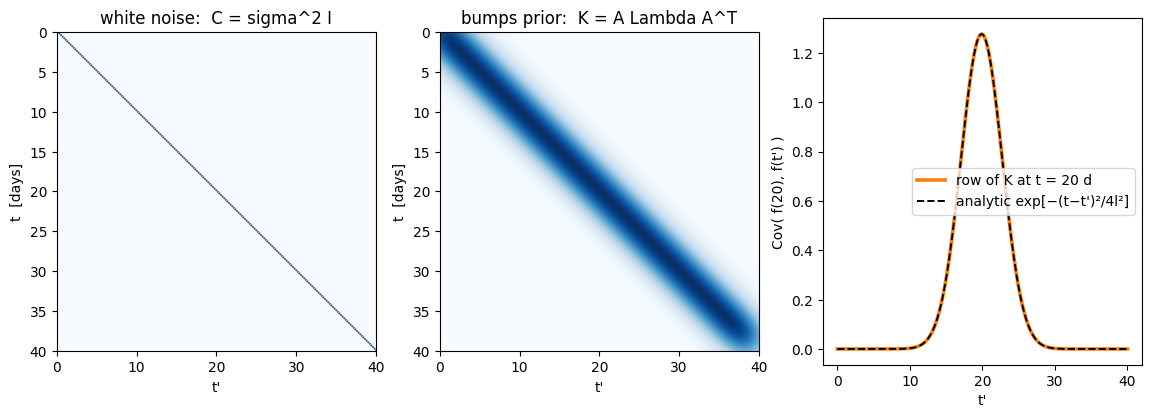

In [121]:
tg = np.linspace(0, 40, 200)
A_g = Phi(tg)
K_grid = lam**2 * A_g @ A_g.T                   # K = A Lambda A^T
K_white = np.eye(tg.size) * K_grid.diagonal().mean()

i0 = np.argmin(np.abs(tg - 20))
k_analytic = lam**2 * np.sqrt(np.pi) * ell / dc * np.exp(-(tg - tg[i0])**2 / (4 * ell**2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
vmax = K_grid.max()
for ax, Kp, ttl in [(axes[0], K_white, "white noise:  C = sigma^2 I"),
                    (axes[1], K_grid, "bumps prior:  K = A Lambda A^T")]:
    ax.imshow(Kp, extent=[0, 40, 40, 0], cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xlabel("t'"); ax.set_ylabel("t  [days]"); ax.set_title(ttl); ax.grid(False)
ax = axes[2]
ax.plot(tg, K_grid[i0], color='C1', lw=2.6, label="row of K at t = 20 d")
ax.plot(tg, k_analytic, color='k', ls="--", lw=1.4, label="analytic exp[−(t−t')²/4l²]")
ax.set_xlabel("t'"); 
ax.set_ylabel("Cov( f(20), f(t') )")
ax.legend()
plt.show()

In [123]:
def k(t1, t2):
    return lam**2 * Phi(t1) @ Phi(t2).T             # k(t, t') = lambda^2 sum_k phi_k(t) phi_k(t')

K    = k(t, t)                  # N x N
Ks   = k(t, tt)                 # N x N*
Kss  = k(tt, tt)                # N* x N*
Cn   = np.diag(sigma**2)        # measurement noise

G    = np.linalg.solve(K + Cn, Ks)                  # (K + C)^-1 K_*
f_fs  = ybar + Ks.T @ np.linalg.solve(K + Cn, yc)   # mean
sd_fs = np.sqrt(np.diag(Kss - Ks.T @ G))            # std

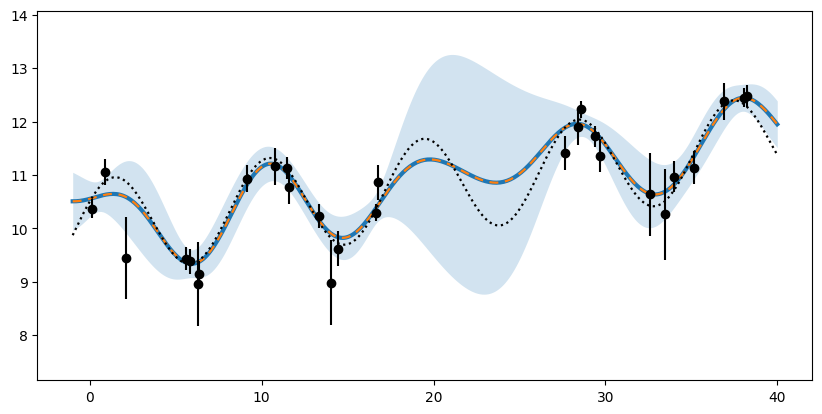

In [129]:
fig, ax = plt.subplots(figsize=(10, 4.8))

ax.fill_between(tt, f_fs - 2*sd_fs, f_fs + 2*sd_fs, color='C0', alpha=0.2, lw=0)
ax.plot(tt, f_fs, color='C0', lw=3, label="function space:  K*ᵀ(K+C)⁻¹y")
ax.plot(tt, f_ws, color='C1', lw=1.6, ls=(0, (4, 3)), label="weight space:  A* μ_post")
ax.plot(tt, true_brightness(tt), color='k', lw=1.6, ls=":", label="the truth")
ax.errorbar(t, y, yerr=sigma, fmt='o', color='black')
ax.set_ylim(y.min() - 1.8, y.max() + 1.6)
plt.show()